In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import libraries

In [ ]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42
HORIZON = 28

np.random.seed(SEED)

print("Step 15 libraries loaded successfully.")

Step 15 libraries loaded successfully.


Define project paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

PREDICTIONS_DIR = os.path.join(
    RESULTS_DIR,
    "predictions"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

FINAL_ANALYSIS_DIR = os.path.join(
    RESULTS_DIR,
    "final_analysis"
)

SHAP_DIR = os.path.join(
    RESULTS_DIR,
    "shap"
)

SHAP_TABLES_DIR = os.path.join(
    SHAP_DIR,
    "tables"
)

FINAL_REPORT_DIR = os.path.join(
    RESULTS_DIR,
    "final_report"
)

FINAL_TABLES_DIR = os.path.join(
    FINAL_REPORT_DIR,
    "tables"
)

FINAL_FIGURES_DIR = os.path.join(
    FINAL_REPORT_DIR,
    "figures"
)

for folder in [
    FINAL_REPORT_DIR,
    FINAL_TABLES_DIR,
    FINAL_FIGURES_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Final report directory:", FINAL_REPORT_DIR)

Final report directory: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_report


Define safe file loader

In [ ]:
def load_csv_safe(path, name):

    if os.path.exists(path):

        df = pd.read_csv(path)

        print(
            f"{name:35s}: FOUND "
            f"{df.shape}"
        )

        return df

    else:

        print(
            f"{name:35s}: MISSING"
        )

        return None

Load complete model comparison

In [ ]:
COMPLETE_MODEL_PATH = os.path.join(
    METRICS_DIR,
    "complete_model_comparison.csv"
)

overall_results = load_csv_safe(
    COMPLETE_MODEL_PATH,
    "Complete model comparison"
)

if overall_results is None:

    raise FileNotFoundError(
        "complete_model_comparison.csv is required. "
        "Run the previous model-comparison step first."
    )

display(
    overall_results.round(4)
)

Complete model comparison          : FOUND (14, 5)


,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398
5,SAE + MLP,0.9248,1.9480,77.9485,125.4724
6,LSTM,0.8332,1.7894,70.2268,127.8854
7,Transformer,0.8384,1.7694,70.6655,133.3020
8,AE + LSTM,0.8476,1.7896,71.4440,114.0228
9,DAE + LSTM,0.8488,1.7909,71.5465,125.3335


Standardize metric columns

In [ ]:
METRICS = [
    "MAE",
    "RMSE",
    "WAPE",
    "sMAPE"
]

for metric in METRICS:

    if metric in overall_results.columns:

        overall_results[metric] = (
            pd.to_numeric(
                overall_results[metric],
                errors="coerce"
            )
        )

print(
    overall_results[
        METRICS
    ].isna().sum()
)

display(
    overall_results.round(4)
)

MAE      0
RMSE     0
WAPE     0
sMAPE    0
dtype: int64


,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398
5,SAE + MLP,0.9248,1.9480,77.9485,125.4724
6,LSTM,0.8332,1.7894,70.2268,127.8854
7,Transformer,0.8384,1.7694,70.6655,133.3020
8,AE + LSTM,0.8476,1.7896,71.4440,114.0228
9,DAE + LSTM,0.8488,1.7909,71.5465,125.3335


Remove accidental duplicate model rows

In [ ]:
overall_results = (
    overall_results
    .drop_duplicates(
        subset=["Model"],
        keep="last"
    )
    .reset_index(drop=True)
)

print(
    "Unique models:",
    overall_results["Model"].nunique()
)

print(
    overall_results["Model"].tolist()
)

Unique models: 14
['Seasonal Naive', 'MLP', 'LightGBM', 'AE + MLP', 'DAE + MLP', 'SAE + MLP', 'LSTM', 'Transformer', 'AE + LSTM', 'DAE + LSTM', 'SAE + LSTM', 'AE + Transformer', 'DAE + Transformer', 'SAE + Transformer']


Create final overall results table

In [ ]:
final_overall = (
    overall_results[
        [
            "Model",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ]
    .copy()
)

final_overall = (
    final_overall
    .sort_values(
        "MAE",
        ascending=True
    )
    .reset_index(drop=True)
)

final_overall.insert(
    0,
    "Observed_MAE_Order",
    np.arange(
        1,
        len(final_overall) + 1
    )
)

display(
    final_overall.round(4)
)

,Observed_MAE_Order,Model,MAE,RMSE,WAPE,sMAPE
0,1,LSTM,0.8332,1.7894,70.2268,127.8854
1,2,DAE + Transformer,0.8372,1.7858,70.5612,119.5099
2,3,Transformer,0.8384,1.7694,70.6655,133.3020
3,4,SAE + Transformer,0.8449,1.7772,71.2111,115.7377
4,5,LightGBM,0.8469,1.8054,71.3810,102.4982
5,6,AE + LSTM,0.8476,1.7896,71.4440,114.0228
6,7,DAE + LSTM,0.8488,1.7909,71.5465,125.3335
7,8,AE + Transformer,0.8590,1.8795,72.4039,126.6875
8,9,SAE + LSTM,0.8819,1.8245,74.3301,132.4461
9,10,MLP,0.9003,1.8435,75.8873,151.5955


Save final overall table

In [ ]:
FINAL_OVERALL_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_01_overall_model_performance.csv"
)

final_overall.to_csv(
    FINAL_OVERALL_PATH,
    index=False
)

print(
    "Saved:",
    FINAL_OVERALL_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_report/tables/table_01_overall_model_performance.csv


Classify model families

In [ ]:
def classify_model(model_name):

    name = str(model_name)

    if name == "Seasonal Naive":
        return "Statistical Baseline"

    elif name == "LightGBM":
        return "Machine Learning"

    elif name == "MLP":
        return "Neural Baseline"

    elif (
        "+ MLP" in name
    ):
        return "Representation + MLP"

    elif (
        name in [
            "LSTM",
            "Transformer"
        ]
    ):
        return "Direct Temporal"

    elif (
        "+ LSTM" in name
        or
        "+ Transformer" in name
    ):
        return "Representation + Temporal"

    else:
        return "Other"


overall_results[
    "Model_Family"
] = (
    overall_results[
        "Model"
    ].apply(
        classify_model
    )
)

display(
    overall_results[
        [
            "Model",
            "Model_Family",
            "MAE",
            "RMSE"
        ]
    ].round(4)
)

,Model,Model_Family,MAE,RMSE
0,Seasonal Naive,Statistical Baseline,1.2555,2.8744
1,MLP,Neural Baseline,0.9003,1.8435
2,LightGBM,Machine Learning,0.8469,1.8054
3,AE + MLP,Representation + MLP,1.0662,1.8089
4,DAE + MLP,Representation + MLP,1.1905,2.8978
5,SAE + MLP,Representation + MLP,0.9248,1.9480
6,LSTM,Direct Temporal,0.8332,1.7894
7,Transformer,Direct Temporal,0.8384,1.7694
8,AE + LSTM,Representation + Temporal,0.8476,1.7896
9,DAE + LSTM,Representation + Temporal,0.8488,1.7909


RQ1: Conventional forecasting performance

How effectively do conventional statistical, machine-learning, and neural-network approaches forecast 28-day retail demand?

In [ ]:
RQ1_MODELS = [
    "Seasonal Naive",
    "LightGBM",
    "MLP"
]

rq1_results = (
    overall_results[
        overall_results[
            "Model"
        ].isin(
            RQ1_MODELS
        )
    ][
        [
            "Model",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ]
    .sort_values(
        "MAE"
    )
    .reset_index(drop=True)
)

display(
    rq1_results.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,LightGBM,0.8469,1.8054,71.3810,102.4982
1,MLP,0.9003,1.8435,75.8873,151.5955
2,Seasonal Naive,1.2555,2.8744,105.8198,86.5290


Calculate RQ1 differences relative to Seasonal Naive

In [ ]:
seasonal_row = rq1_results[
    rq1_results["Model"]
    ==
    "Seasonal Naive"
]

if len(seasonal_row) > 0:

    seasonal_mae = float(
        seasonal_row.iloc[0]["MAE"]
    )

    rq1_results[
        "MAE_Change_vs_Seasonal_Naive_Pct"
    ] = (
        (
            seasonal_mae
            -
            rq1_results["MAE"]
        )
        /
        seasonal_mae
    ) * 100

else:

    rq1_results[
        "MAE_Change_vs_Seasonal_Naive_Pct"
    ] = np.nan

display(
    rq1_results.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE,MAE_Change_vs_Seasonal_Naive_Pct
0,LightGBM,0.8469,1.8054,71.3810,102.4982,32.5447
1,MLP,0.9003,1.8435,75.8873,151.5955,28.2863
2,Seasonal Naive,1.2555,2.8744,105.8198,86.5290,0.0000


In [ ]:
RQ1_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_02_rq1_baseline_comparison.csv"
)

rq1_results.to_csv(
    RQ1_PATH,
    index=False
)

RQ2: Does representation learning change forecasting performance?

Does autoencoder-based representation learning improve forecasting performance compared with the original engineered feature space?

In [ ]:
RQ2_MODELS = [
    "MLP",
    "AE + MLP",
    "DAE + MLP",
    "SAE + MLP"
]

rq2_results = (
    overall_results[
        overall_results[
            "Model"
        ].isin(
            RQ2_MODELS
        )
    ][
        [
            "Model",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ]
    .copy()
)

mlp_row = rq2_results[
    rq2_results["Model"] == "MLP"
]

if len(mlp_row) > 0:

    mlp_mae = float(
        mlp_row.iloc[0]["MAE"]
    )

    rq2_results[
        "MAE_Change_vs_MLP_Pct"
    ] = (
        (
            mlp_mae
            -
            rq2_results["MAE"]
        )
        /
        mlp_mae
    ) * 100

else:

    rq2_results[
        "MAE_Change_vs_MLP_Pct"
    ] = np.nan

rq2_results = (
    rq2_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    rq2_results.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE,MAE_Change_vs_MLP_Pct
0,MLP,0.9003,1.8435,75.8873,151.5955,0.0000
1,SAE + MLP,0.9248,1.9480,77.9485,125.4724,-2.7162
2,AE + MLP,1.0662,1.8089,89.8639,136.1644,-18.4177
3,DAE + MLP,1.1905,2.8978,100.3419,128.1398,-32.2250


In [ ]:
RQ2_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_03_rq2_representation_learning.csv"
)

rq2_results.to_csv(
    RQ2_PATH,
    index=False
)

RQ3: Compare AE, DAE, and Sparse Autoencoder

How do AE, DAE, and Sparse Autoencoder representations differ in reconstruction characteristics and downstream forecasting performance?

In [ ]:
AE_RECON_PATH = os.path.join(
    METRICS_DIR,
    "ae_reconstruction_metrics.csv"
)

DAE_RECON_PATH = os.path.join(
    METRICS_DIR,
    "dae_reconstruction_metrics.csv"
)

SAE_RECON_PATH = os.path.join(
    METRICS_DIR,
    "sae_reconstruction_metrics.csv"
)

ae_recon = load_csv_safe(
    AE_RECON_PATH,
    "AE reconstruction"
)

dae_recon = load_csv_safe(
    DAE_RECON_PATH,
    "DAE reconstruction"
)

sae_recon = load_csv_safe(
    SAE_RECON_PATH,
    "SAE reconstruction"
)

AE reconstruction                  : FOUND (3, 3)
DAE reconstruction                 : FOUND (3, 3)
SAE reconstruction                 : FOUND (3, 3)


Create downstream AE/DAE/SAE comparison

In [ ]:
representation_mlp_models = [
    "AE + MLP",
    "DAE + MLP",
    "SAE + MLP"
]

rq3_forecast = (
    overall_results[
        overall_results[
            "Model"
        ].isin(
            representation_mlp_models
        )
    ][
        [
            "Model",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ]
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    rq3_forecast.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,SAE + MLP,0.9248,1.9480,77.9485,125.4724
1,AE + MLP,1.0662,1.8089,89.8639,136.1644
2,DAE + MLP,1.1905,2.8978,100.3419,128.1398


In [ ]:
RQ3_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_04_rq3_autoencoder_forecasting.csv"
)

rq3_forecast.to_csv(
    RQ3_PATH,
    index=False
)

Load SAE sparsity statistics if available

In [ ]:
possible_sae_files = [
    os.path.join(
        METRICS_DIR,
        "sae_sparsity_statistics.csv"
    ),
    os.path.join(
        METRICS_DIR,
        "sae_sparsity_metrics.csv"
    )
]

sae_sparsity = None

for path in possible_sae_files:

    if os.path.exists(path):

        sae_sparsity = pd.read_csv(path)

        print(
            "SAE sparsity statistics found:",
            path
        )

        display(
            sae_sparsity.round(6)
        )

        break

if sae_sparsity is None:

    print(
        "No separate SAE sparsity statistics file found."
    )

No separate SAE sparsity statistics file found.


RQ4: Latent representations with LSTM and Transformer

How effectively can AE, DAE, and SAE latent representations be combined with LSTM and Transformer architectures for 28-day forecasting

In [ ]:
RQ4_MODELS = [
    "AE + LSTM",
    "DAE + LSTM",
    "SAE + LSTM",
    "AE + Transformer",
    "DAE + Transformer",
    "SAE + Transformer"
]

rq4_results = (
    overall_results[
        overall_results[
            "Model"
        ].isin(
            RQ4_MODELS
        )
    ][
        [
            "Model",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ]
    .copy()
)

rq4_results = (
    rq4_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    rq4_results.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,DAE + Transformer,0.8372,1.7858,70.5612,119.5099
1,SAE + Transformer,0.8449,1.7772,71.2111,115.7377
2,AE + LSTM,0.8476,1.7896,71.4440,114.0228
3,DAE + LSTM,0.8488,1.7909,71.5465,125.3335
4,AE + Transformer,0.8590,1.8795,72.4039,126.6875
5,SAE + LSTM,0.8819,1.8245,74.3301,132.4461


In [ ]:
RQ4_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_05_rq4_latent_temporal_models.csv"
)

rq4_results.to_csv(
    RQ4_PATH,
    index=False
)

Separate representation and temporal architecture

In [ ]:
rq4_decomposition = (
    rq4_results.copy()
)

rq4_decomposition[
    "Representation"
] = (
    rq4_decomposition[
        "Model"
    ]
    .str.split(
        " + ",
        regex=False
    )
    .str[0]
)

rq4_decomposition[
    "Temporal_Model"
] = (
    rq4_decomposition[
        "Model"
    ]
    .str.split(
        " + ",
        regex=False
    )
    .str[1]
)

display(
    rq4_decomposition.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE,Representation,Temporal_Model
0,DAE + Transformer,0.8372,1.7858,70.5612,119.5099,DAE,Transformer
1,SAE + Transformer,0.8449,1.7772,71.2111,115.7377,SAE,Transformer
2,AE + LSTM,0.8476,1.7896,71.4440,114.0228,AE,LSTM
3,DAE + LSTM,0.8488,1.7909,71.5465,125.3335,DAE,LSTM
4,AE + Transformer,0.8590,1.8795,72.4039,126.6875,AE,Transformer
5,SAE + LSTM,0.8819,1.8245,74.3301,132.4461,SAE,LSTM


Create AE/DAE/SAE × LSTM/Transformer matrix

In [ ]:
rq4_matrix = (
    rq4_decomposition
    .pivot(
        index="Representation",
        columns="Temporal_Model",
        values="MAE"
    )
)

display(
    rq4_matrix.round(4)
)

Temporal_Model,LSTM,Transformer
Representation,,
AE,0.8476,0.8590
DAE,0.8488,0.8372
SAE,0.8819,0.8449


In [ ]:
RQ4_MATRIX_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_06_representation_temporal_mae_matrix.csv"
)

rq4_matrix.to_csv(
    RQ4_MATRIX_PATH
)

Compare direct vs latent temporal models

In [ ]:
TEMPORAL_MODELS = [
    "LSTM",
    "Transformer",
    "AE + LSTM",
    "DAE + LSTM",
    "SAE + LSTM",
    "AE + Transformer",
    "DAE + Transformer",
    "SAE + Transformer"
]

temporal_comparison = (
    overall_results[
        overall_results[
            "Model"
        ].isin(
            TEMPORAL_MODELS
        )
    ][
        [
            "Model",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ]
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    temporal_comparison.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,LSTM,0.8332,1.7894,70.2268,127.8854
1,DAE + Transformer,0.8372,1.7858,70.5612,119.5099
2,Transformer,0.8384,1.7694,70.6655,133.3020
3,SAE + Transformer,0.8449,1.7772,71.2111,115.7377
4,AE + LSTM,0.8476,1.7896,71.4440,114.0228
5,DAE + LSTM,0.8488,1.7909,71.5465,125.3335
6,AE + Transformer,0.8590,1.8795,72.4039,126.6875
7,SAE + LSTM,0.8819,1.8245,74.3301,132.4461


In [ ]:
TEMPORAL_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_07_direct_vs_latent_temporal.csv"
)

temporal_comparison.to_csv(
    TEMPORAL_PATH,
    index=False
)

Quantify hybrid changes relative to direct LSTM/Transformer

In [ ]:
hybrid_rows = []

for architecture in [
    "LSTM",
    "Transformer"
]:

    direct = overall_results[
        overall_results[
            "Model"
        ] == architecture
    ]

    if len(direct) == 0:
        continue

    direct_mae = float(
        direct.iloc[0]["MAE"]
    )

    for representation in [
        "AE",
        "DAE",
        "SAE"
    ]:

        hybrid_name = (
            f"{representation} + {architecture}"
        )

        hybrid = overall_results[
            overall_results[
                "Model"
            ] == hybrid_name
        ]

        if len(hybrid) == 0:
            continue

        hybrid_mae = float(
            hybrid.iloc[0]["MAE"]
        )

        change = (
            (
                direct_mae
                -
                hybrid_mae
            )
            /
            direct_mae
        ) * 100

        hybrid_rows.append({
            "Temporal_Model":
                architecture,

            "Representation":
                representation,

            "Direct_Model":
                architecture,

            "Hybrid_Model":
                hybrid_name,

            "Direct_MAE":
                direct_mae,

            "Hybrid_MAE":
                hybrid_mae,

            "MAE_Change_Pct":
                change
        })


hybrid_changes = pd.DataFrame(
    hybrid_rows
)

display(
    hybrid_changes.round(4)
)

,Temporal_Model,Representation,Direct_Model,Hybrid_Model,Direct_MAE,Hybrid_MAE,MAE_Change_Pct
0,LSTM,AE,LSTM,AE + LSTM,0.8332,0.8476,-1.7333
1,LSTM,DAE,LSTM,DAE + LSTM,0.8332,0.8488,-1.8792
2,LSTM,SAE,LSTM,SAE + LSTM,0.8332,0.8819,-5.8429
3,Transformer,AE,Transformer,AE + Transformer,0.8384,0.8590,-2.4600
4,Transformer,DAE,Transformer,DAE + Transformer,0.8384,0.8372,0.1476
5,Transformer,SAE,Transformer,SAE + Transformer,0.8384,0.8449,-0.7721


In [ ]:
HYBRID_CHANGE_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_08_hybrid_vs_direct_change.csv"
)

hybrid_changes.to_csv(
    HYBRID_CHANGE_PATH,
    index=False
)

RQ5: Load multi-level evaluation

How does forecasting performance vary across stores, categories, departments, states, and forecast horizons?

In [ ]:
STORE_PATH = os.path.join(
    FINAL_ANALYSIS_DIR,
    "store_level_results.csv"
)

CATEGORY_PATH = os.path.join(
    FINAL_ANALYSIS_DIR,
    "category_level_results.csv"
)

DEPARTMENT_PATH = os.path.join(
    FINAL_ANALYSIS_DIR,
    "department_level_results.csv"
)

STATE_PATH = os.path.join(
    FINAL_ANALYSIS_DIR,
    "state_level_results.csv"
)

HORIZON_PATH = os.path.join(
    FINAL_ANALYSIS_DIR,
    "forecast_horizon_results.csv"
)

HORIZON_GROUP_PATH = os.path.join(
    FINAL_ANALYSIS_DIR,
    "short_medium_long_horizon_results.csv"
)

store_results = load_csv_safe(
    STORE_PATH,
    "Store results"
)

category_results = load_csv_safe(
    CATEGORY_PATH,
    "Category results"
)

department_results = load_csv_safe(
    DEPARTMENT_PATH,
    "Department results"
)

state_results = load_csv_safe(
    STATE_PATH,
    "State results"
)

horizon_results = load_csv_safe(
    HORIZON_PATH,
    "Horizon results"
)

horizon_group_results = load_csv_safe(
    HORIZON_GROUP_PATH,
    "Horizon group results"
)

Store results                      : FOUND (60, 7)
Category results                   : FOUND (18, 7)
Department results                 : FOUND (42, 7)
State results                      : FOUND (18, 7)
Horizon results                    : FOUND (168, 7)
Horizon group results              : FOUND (18, 7)


Store-level summary

In [ ]:
if store_results is not None:

    store_summary = (
        store_results
        .groupby("Model")
        .agg(
            Mean_Store_MAE=("MAE", "mean"),
            Median_Store_MAE=("MAE", "median"),
            Std_Store_MAE=("MAE", "std"),
            Min_Store_MAE=("MAE", "min"),
            Max_Store_MAE=("MAE", "max")
        )
        .reset_index()
        .sort_values(
            "Mean_Store_MAE"
        )
    )

    display(
        store_summary.round(4)
    )

    STORE_SUMMARY_PATH = os.path.join(
        FINAL_TABLES_DIR,
        "table_09_store_summary.csv"
    )

    store_summary.to_csv(
        STORE_SUMMARY_PATH,
        index=False
    )

,Model,Mean_Store_MAE,Median_Store_MAE,Std_Store_MAE,Min_Store_MAE,Max_Store_MAE
3,DAE + Transformer,0.8700,0.8344,0.3210,0.5260,1.6266
5,SAE + Transformer,0.8765,0.8130,0.3131,0.5828,1.6407
0,AE + LSTM,0.8806,0.8268,0.3223,0.5364,1.6537
2,DAE + LSTM,0.8831,0.8313,0.3209,0.5324,1.6345
1,AE + Transformer,0.8943,0.8377,0.3522,0.5357,1.7341
4,SAE + LSTM,0.9135,0.8283,0.3247,0.6143,1.7142


Category-level final table

In [ ]:
if category_results is not None:

    category_final = (
        category_results[
            [
                "Model",
                "cat_id",
                "MAE",
                "RMSE",
                "WAPE",
                "sMAPE"
            ]
        ]
        .copy()
    )

    category_final = (
        category_final
        .sort_values(
            [
                "cat_id",
                "MAE"
            ]
        )
    )

    display(
        category_final.round(4)
    )

    CATEGORY_FINAL_PATH = os.path.join(
        FINAL_TABLES_DIR,
        "table_10_category_performance.csv"
    )

    category_final.to_csv(
        CATEGORY_FINAL_PATH,
        index=False
    )

,Model,cat_id,MAE,RMSE,WAPE,sMAPE
5,SAE + Transformer,FOODS,1.0094,2.0711,64.6287,112.0585
3,DAE + Transformer,FOODS,1.0181,2.0761,65.1853,116.6862
0,AE + LSTM,FOODS,1.0259,2.0863,65.6865,110.8333
2,DAE + LSTM,FOODS,1.0266,2.0742,65.7311,120.5298
1,AE + Transformer,FOODS,1.0437,2.2265,66.8267,121.9748
4,SAE + LSTM,FOODS,1.0646,2.1338,68.1635,131.3246
9,DAE + Transformer,HOBBIES,0.6343,1.5111,89.7186,127.0876
7,AE + Transformer,HOBBIES,0.6510,1.4923,92.0841,136.6877
6,AE + LSTM,HOBBIES,0.6517,1.4869,92.1873,121.3886
8,DAE + LSTM,HOBBIES,0.6561,1.5352,92.8074,135.0728


State-level final table

In [ ]:
if state_results is not None:

    state_final = (
        state_results[
            [
                "Model",
                "state_id",
                "MAE",
                "RMSE",
                "WAPE",
                "sMAPE"
            ]
        ]
        .sort_values(
            [
                "state_id",
                "MAE"
            ]
        )
    )

    display(
        state_final.round(4)
    )

    STATE_FINAL_PATH = os.path.join(
        FINAL_TABLES_DIR,
        "table_11_state_performance.csv"
    )

    state_final.to_csv(
        STATE_FINAL_PATH,
        index=False
    )

,Model,state_id,MAE,RMSE,WAPE,sMAPE
5,SAE + Transformer,CA,1.0178,2.2471,63.7307,109.9484
3,DAE + Transformer,CA,1.0289,2.2190,64.4278,113.6278
0,AE + LSTM,CA,1.0485,2.2739,65.6534,111.3624
2,DAE + LSTM,CA,1.0577,2.2659,66.2271,124.4650
1,AE + Transformer,CA,1.0664,2.4261,66.7766,120.5048
4,SAE + LSTM,CA,1.0752,2.2963,67.3232,129.5153
8,DAE + LSTM,TX,0.6755,1.4169,71.8410,125.4386
9,DAE + Transformer,TX,0.6768,1.4499,71.9768,121.3451
6,AE + LSTM,TX,0.6780,1.4118,72.1056,114.9267
7,AE + Transformer,TX,0.6927,1.4668,73.6711,131.6380


Horizon-group final table

In [ ]:
if horizon_group_results is not None:

    horizon_group_final = (
        horizon_group_results[
            [
                "Model",
                "Horizon_Group",
                "MAE",
                "RMSE",
                "WAPE",
                "sMAPE"
            ]
        ]
        .copy()
    )

    display(
        horizon_group_final.round(4)
    )

    HORIZON_FINAL_PATH = os.path.join(
        FINAL_TABLES_DIR,
        "table_12_horizon_group_performance.csv"
    )

    horizon_group_final.to_csv(
        HORIZON_FINAL_PATH,
        index=False
    )

,Model,Horizon_Group,MAE,RMSE,WAPE,sMAPE
0,AE + LSTM,Day 1-7,0.8279,1.8283,74.8396,111.3444
1,AE + LSTM,Day 15-28,0.8921,1.8523,71.0189,112.5553
2,AE + LSTM,Day 8-14,0.7784,1.6142,69.0591,119.6361
3,AE + Transformer,Day 1-7,0.8275,1.9252,74.8074,126.5832
4,AE + Transformer,Day 15-28,0.9082,1.9434,72.2968,127.5334
5,AE + Transformer,Day 8-14,0.7922,1.6943,70.2837,125.0999
6,DAE + LSTM,Day 1-7,0.8120,1.8005,73.4039,82.6337
7,DAE + LSTM,Day 15-28,0.8992,1.8631,71.5785,140.3566
8,DAE + LSTM,Day 8-14,0.7851,1.6266,69.6523,137.9871
9,DAE + Transformer,Day 1-7,0.8075,1.7962,73.0001,109.6294


Plot 28-day error trajectories

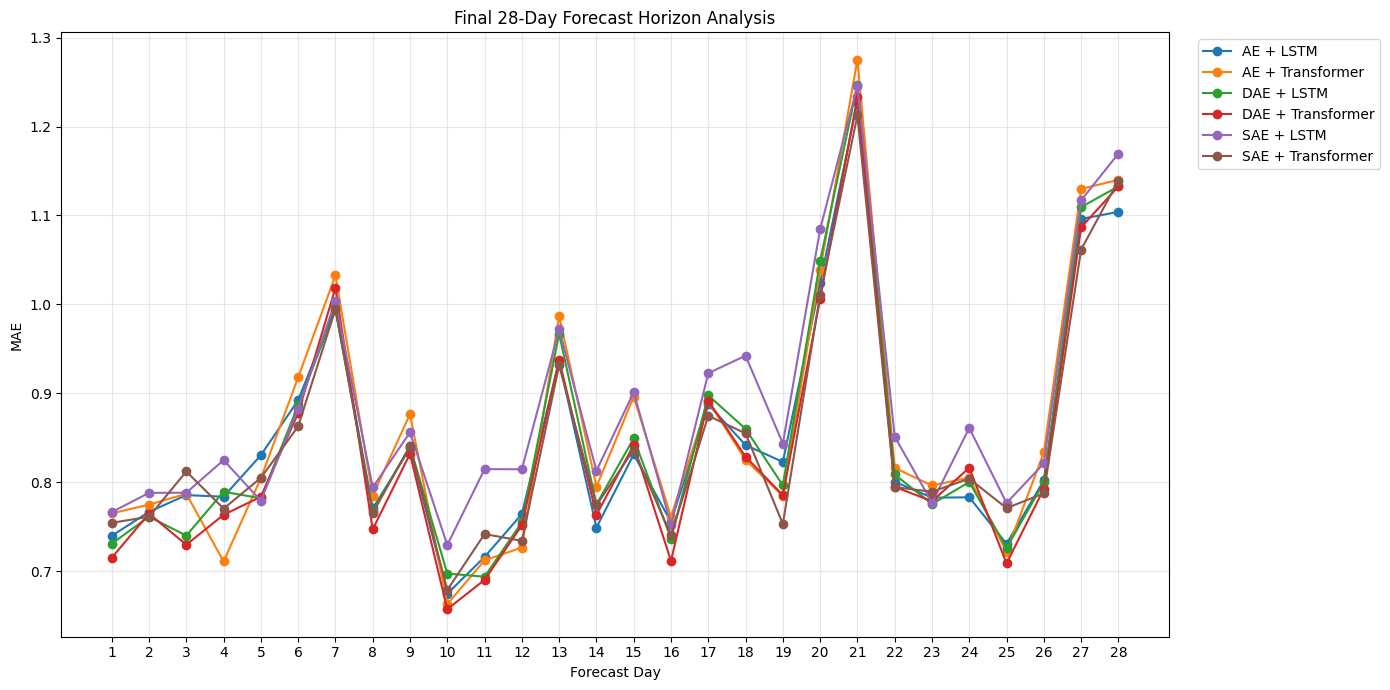

In [ ]:
if horizon_results is not None:

    horizon_mae = (
        horizon_results
        .pivot(
            index="forecast_day",
            columns="Model",
            values="MAE"
        )
    )

    plt.figure(
        figsize=(14, 7)
    )

    for model in horizon_mae.columns:

        plt.plot(
            horizon_mae.index,
            horizon_mae[model],
            marker="o",
            label=model
        )

    plt.xlabel(
        "Forecast Day"
    )

    plt.ylabel(
        "MAE"
    )

    plt.title(
        "Final 28-Day Forecast Horizon Analysis"
    )

    plt.xticks(
        np.arange(
            1,
            29
        )
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend(
        bbox_to_anchor=(
            1.02,
            1
        ),
        loc="upper left"
    )

    plt.tight_layout()

    FINAL_HORIZON_FIG = os.path.join(
        FINAL_FIGURES_DIR,
        "figure_01_28day_horizon_analysis.png"
    )

    plt.savefig(
        FINAL_HORIZON_FIG,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

RQ6: Load SHAP explainability results

Which engineered variables contribute most strongly to LightGBM demand forecasts, and how does their influence change across the forecast horizon?

In [ ]:
GLOBAL_SHAP_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "global_shap_feature_importance.csv"
)

FEATURE_GROUP_SHAP_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "shap_feature_group_importance.csv"
)

HORIZON_SHAP_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "shap_short_medium_long_horizon.csv"
)

DAYWISE_SHAP_PATH = os.path.join(
    SHAP_TABLES_DIR,
    "daywise_shap_feature_importance.csv"
)

global_shap = load_csv_safe(
    GLOBAL_SHAP_PATH,
    "Global SHAP importance"
)

feature_group_shap = load_csv_safe(
    FEATURE_GROUP_SHAP_PATH,
    "SHAP feature groups"
)

horizon_shap = load_csv_safe(
    HORIZON_SHAP_PATH,
    "SHAP horizon groups"
)

daywise_shap = load_csv_safe(
    DAYWISE_SHAP_PATH,
    "Day-wise SHAP"
)

Global SHAP importance             : FOUND (40, 3)
SHAP feature groups                : FOUND (8, 4)
SHAP horizon groups                : FOUND (120, 3)
Day-wise SHAP                      : FOUND (1120, 3)


Final top-15 SHAP table

In [ ]:
if global_shap is not None:

    rq6_top_features = (
        global_shap
        .head(15)
        .copy()
    )

    display(
        rq6_top_features.round(6)
    )

    RQ6_TOP_PATH = os.path.join(
        FINAL_TABLES_DIR,
        "table_13_rq6_top_shap_features.csv"
    )

    rq6_top_features.to_csv(
        RQ6_TOP_PATH,
        index=False
    )

,Rank,Feature,Mean_Abs_SHAP
0,1,rolling_mean_28,0.372954
1,2,rolling_mean_14,0.288295
2,3,rolling_mean_7,0.139384
3,4,rolling_std_28,0.088617
4,5,demand_ratio_7_28,0.039634
5,6,lag_1,0.025076
6,7,store_id_code,0.018372
7,8,day_of_month,0.017280
8,9,sell_price,0.017075
9,10,rolling_std_7,0.015965


Feature-family SHAP table

In [ ]:
if feature_group_shap is not None:

    rq6_groups = (
        feature_group_shap
        .sort_values(
            "Total_Mean_Abs_SHAP",
            ascending=False
        )
        .reset_index(drop=True)
    )

    display(
        rq6_groups.round(6)
    )

    RQ6_GROUP_PATH = os.path.join(
        FINAL_TABLES_DIR,
        "table_14_rq6_feature_family_shap.csv"
    )

    rq6_groups.to_csv(
        RQ6_GROUP_PATH,
        index=False
    )

,Feature_Group,Number_of_Features,Total_Mean_Abs_SHAP,Average_Mean_Abs_SHAP
0,Rolling Demand,7,0.948857,0.135551
1,Lag Features,4,0.039204,0.009801
2,Hierarchy,5,0.036192,0.007238
3,Calendar,7,0.025511,0.003644
4,Price,4,0.017645,0.004411
5,Cyclical Time,6,0.007271,0.001212
6,SNAP,4,0.001981,0.000495
7,Events,3,0.000061,0.000020


Top feature in each SHAP horizon group

In [ ]:
if horizon_shap is not None:

    rq6_horizon_top = (
        horizon_shap
        .sort_values(
            [
                "Horizon_Group",
                "Mean_Abs_SHAP"
            ],
            ascending=[
                True,
                False
            ]
        )
        .groupby(
            "Horizon_Group"
        )
        .head(10)
        .reset_index(drop=True)
    )

    display(
        rq6_horizon_top.round(6)
    )

    RQ6_HORIZON_PATH = os.path.join(
        FINAL_TABLES_DIR,
        "table_15_rq6_horizon_shap.csv"
    )

    rq6_horizon_top.to_csv(
        RQ6_HORIZON_PATH,
        index=False
    )

,Horizon_Group,Feature,Mean_Abs_SHAP
0,Long_15_28,rolling_mean_28,0.337619
1,Long_15_28,rolling_mean_14,0.313008
2,Long_15_28,rolling_mean_7,0.132259
3,Long_15_28,rolling_std_28,0.101984
4,Long_15_28,demand_ratio_7_28,0.031676
5,Long_15_28,store_id_code,0.021267
6,Long_15_28,sell_price,0.018565
7,Long_15_28,item_id_code,0.015981
8,Long_15_28,rolling_std_7,0.015110
9,Long_15_28,day_of_month,0.013888


Statistical comparison from Step 13

In [ ]:
STATISTICAL_PATH = os.path.join(
    FINAL_ANALYSIS_DIR,
    "pairwise_wilcoxon_results.csv"
)

statistical_results = load_csv_safe(
    STATISTICAL_PATH,
    "Wilcoxon comparisons"
)

if statistical_results is not None:

    display(
        statistical_results.round(6)
    )

    FINAL_STATS_PATH = os.path.join(
        FINAL_TABLES_DIR,
        "table_16_pairwise_statistical_tests.csv"
    )

    statistical_results.to_csv(
        FINAL_STATS_PATH,
        index=False
    )

Wilcoxon comparisons               : MISSING


Identify minimum observed test error values

In [ ]:
metric_minimum_rows = []

for metric in METRICS:

    valid = (
        overall_results[
            [
                "Model",
                metric
            ]
        ]
        .dropna()
    )

    if len(valid) == 0:
        continue

    minimum_index = (
        valid[metric]
        .idxmin()
    )

    metric_minimum_rows.append({

        "Metric":
            metric,

        "Model_with_Minimum_Observed_Error":
            overall_results.loc[
                minimum_index,
                "Model"
            ],

        "Minimum_Observed_Value":
            overall_results.loc[
                minimum_index,
                metric
            ]
    })


metric_minimums = pd.DataFrame(
    metric_minimum_rows
)

display(
    metric_minimums.round(4)
)

,Metric,Model_with_Minimum_Observed_Error,Minimum_Observed_Value
0,MAE,LSTM,0.8332
1,RMSE,Transformer,1.7694
2,WAPE,LSTM,70.2268
3,sMAPE,Seasonal Naive,86.5290


In [ ]:
METRIC_MINIMUM_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_17_minimum_observed_error_by_metric.csv"
)

metric_minimums.to_csv(
    METRIC_MINIMUM_PATH,
    index=False
)

Create model-family summary

In [ ]:
family_summary = (
    overall_results
    .groupby(
        "Model_Family"
    )
    .agg(
        Number_of_Models=(
            "Model",
            "count"
        ),

        Mean_MAE=(
            "MAE",
            "mean"
        ),

        Median_MAE=(
            "MAE",
            "median"
        ),

        Mean_RMSE=(
            "RMSE",
            "mean"
        ),

        Mean_WAPE=(
            "WAPE",
            "mean"
        ),

        Mean_sMAPE=(
            "sMAPE",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        "Mean_MAE"
    )
)

display(
    family_summary.round(4)
)

,Model_Family,Number_of_Models,Mean_MAE,Median_MAE,Mean_RMSE,Mean_WAPE,Mean_sMAPE
0,Direct Temporal,2,0.8358,0.8358,1.7794,70.4462,130.5937
1,Machine Learning,1,0.8469,0.8469,1.8054,71.3810,102.4982
4,Representation + Temporal,6,0.8532,0.8482,1.8079,71.9161,122.2896
2,Neural Baseline,1,0.9003,0.9003,1.8435,75.8873,151.5955
3,Representation + MLP,3,1.0605,1.0662,2.2182,89.3848,129.9255
5,Statistical Baseline,1,1.2555,1.2555,2.8744,105.8198,86.5290


In [ ]:
FAMILY_SUMMARY_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_18_model_family_summary.csv"
)

family_summary.to_csv(
    FAMILY_SUMMARY_PATH,
    index=False
)

Overall performance figure

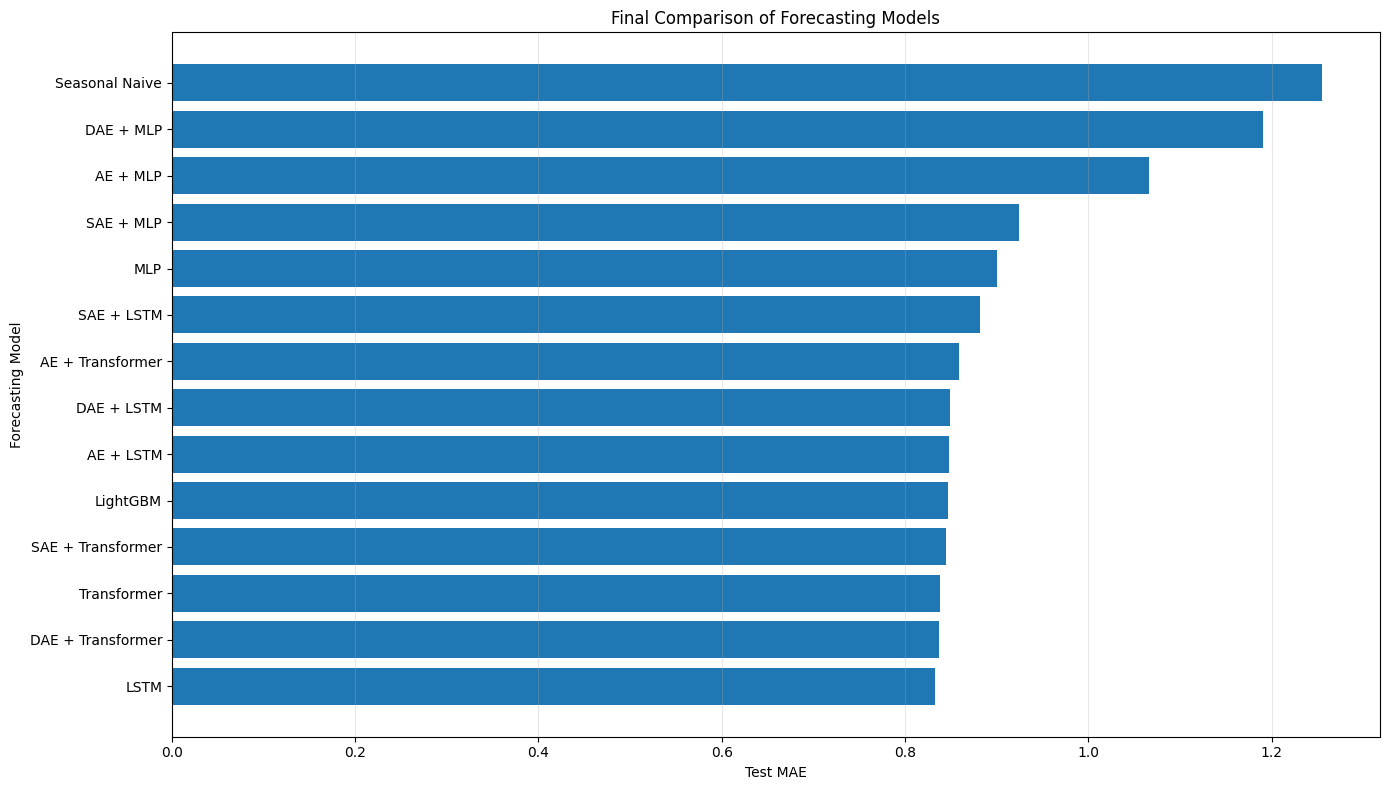

In [ ]:
plot_df = (
    overall_results
    .sort_values(
        "MAE",
        ascending=True
    )
)

plt.figure(
    figsize=(14, 8)
)

plt.barh(
    plot_df["Model"],
    plot_df["MAE"]
)

plt.xlabel(
    "Test MAE"
)

plt.ylabel(
    "Forecasting Model"
)

plt.title(
    "Final Comparison of Forecasting Models"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

OVERALL_FIG = os.path.join(
    FINAL_FIGURES_DIR,
    "figure_02_final_model_mae_comparison.png"
)

plt.savefig(
    OVERALL_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Representation-learning comparison figure

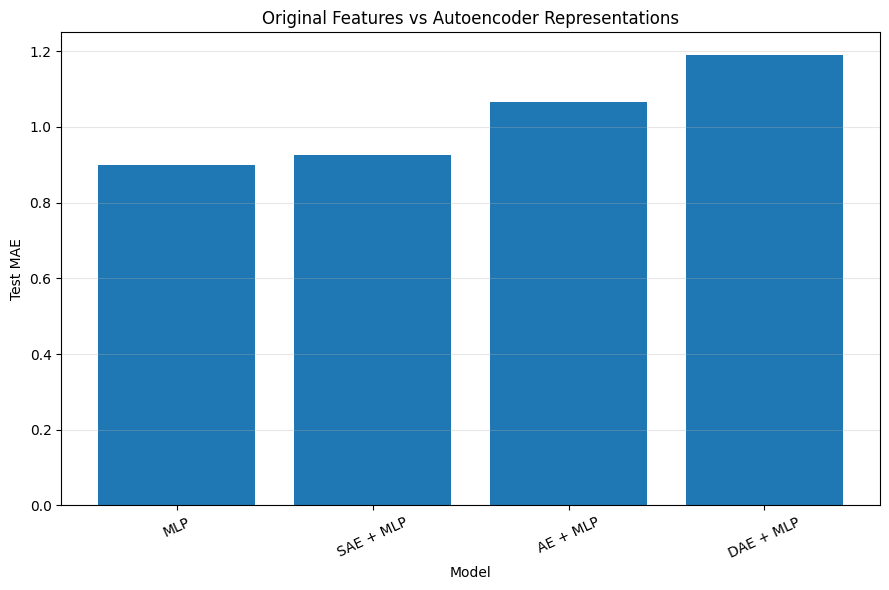

In [ ]:
representation_plot = (
    overall_results[
        overall_results[
            "Model"
        ].isin([
            "MLP",
            "AE + MLP",
            "DAE + MLP",
            "SAE + MLP"
        ])
    ]
    .sort_values("MAE")
)

if len(representation_plot) > 0:

    plt.figure(
        figsize=(9, 6)
    )

    plt.bar(
        representation_plot[
            "Model"
        ],
        representation_plot[
            "MAE"
        ]
    )

    plt.xlabel(
        "Model"
    )

    plt.ylabel(
        "Test MAE"
    )

    plt.title(
        "Original Features vs Autoencoder Representations"
    )

    plt.xticks(
        rotation=25
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    REPRESENTATION_FIG = os.path.join(
        FINAL_FIGURES_DIR,
        "figure_03_representation_learning_comparison.png"
    )

    plt.savefig(
        REPRESENTATION_FIG,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

LSTM vs Transformer representation figure

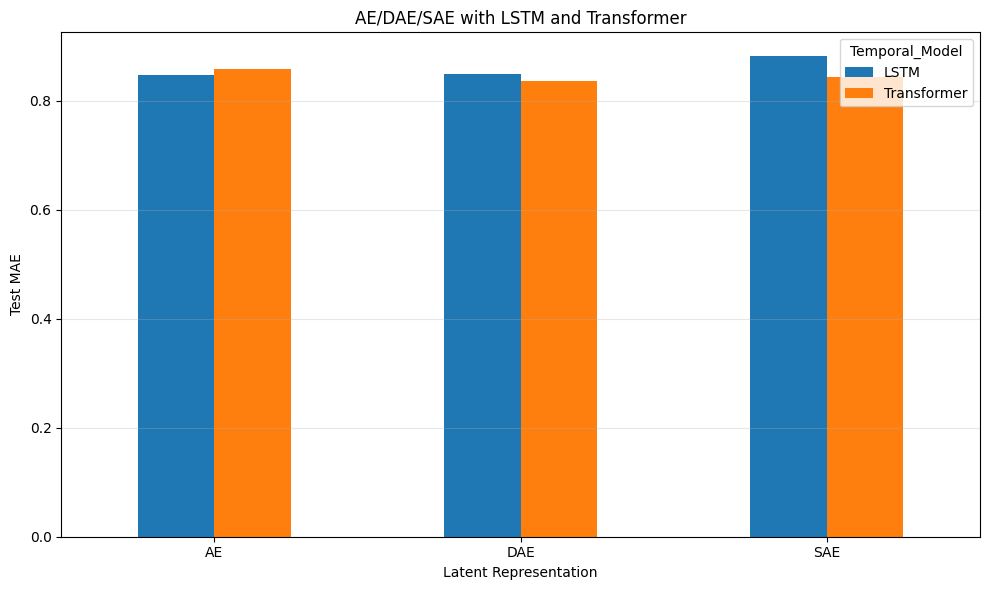

In [ ]:
if len(rq4_decomposition) > 0:

    rq4_plot = (
        rq4_decomposition
        .pivot(
            index="Representation",
            columns="Temporal_Model",
            values="MAE"
        )
    )

    rq4_plot.plot(
        kind="bar",
        figsize=(10, 6)
    )

    plt.xlabel(
        "Latent Representation"
    )

    plt.ylabel(
        "Test MAE"
    )

    plt.title(
        "AE/DAE/SAE with LSTM and Transformer"
    )

    plt.xticks(
        rotation=0
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    TEMPORAL_FIG = os.path.join(
        FINAL_FIGURES_DIR,
        "figure_04_latent_temporal_comparison.png"
    )

    plt.savefig(
        TEMPORAL_FIG,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Final SHAP figure

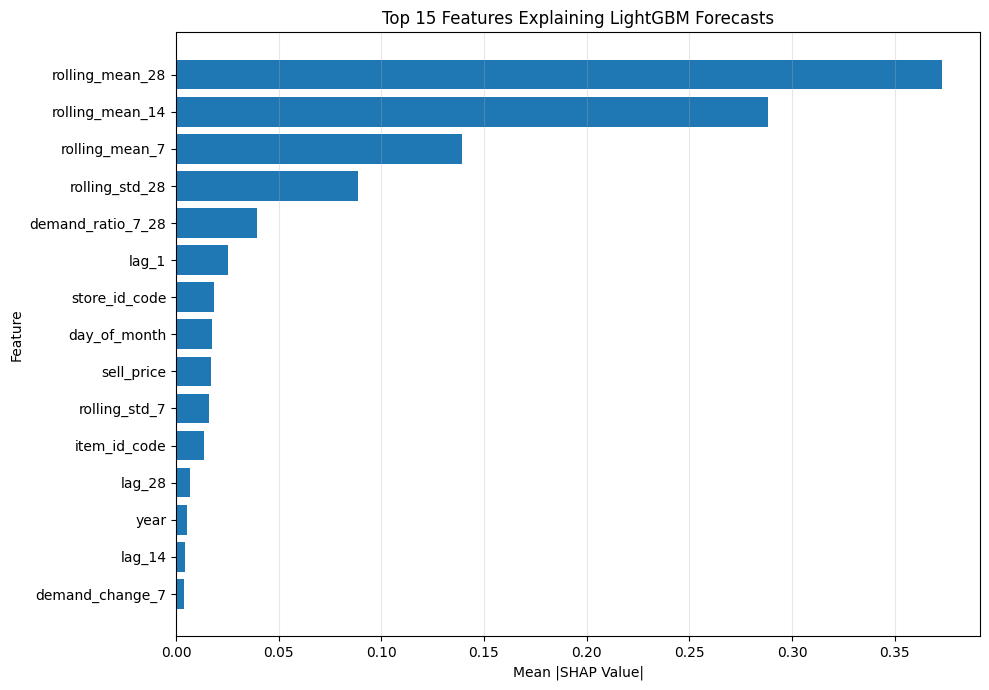

In [ ]:
if global_shap is not None:

    shap_plot = (
        global_shap
        .head(15)
        .sort_values(
            "Mean_Abs_SHAP"
        )
    )

    plt.figure(
        figsize=(10, 7)
    )

    plt.barh(
        shap_plot["Feature"],
        shap_plot["Mean_Abs_SHAP"]
    )

    plt.xlabel(
        "Mean |SHAP Value|"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        "Top 15 Features Explaining "
        "LightGBM Forecasts"
    )

    plt.grid(
        axis="x",
        alpha=0.3
    )

    plt.tight_layout()

    FINAL_SHAP_FIG = os.path.join(
        FINAL_FIGURES_DIR,
        "figure_05_final_shap_importance.png"
    )

    plt.savefig(
        FINAL_SHAP_FIG,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Automatically create RQ1 result statement

In [ ]:
research_findings = []

if len(rq1_results) > 0:

    rq1_min = (
        rq1_results
        .sort_values("MAE")
        .iloc[0]
    )

    rq1_text = (
        f"RQ1: Among the evaluated conventional "
        f"baselines, {rq1_min['Model']} produced "
        f"the minimum observed MAE of "
        f"{rq1_min['MAE']:.4f} on the test set."
    )

    research_findings.append(
        rq1_text
    )

    print(rq1_text)

RQ1: Among the evaluated conventional baselines, LightGBM produced the minimum observed MAE of 0.8469 on the test set.


Automatically create RQ2 statement

In [ ]:
if len(rq2_results) > 0:

    rq2_min = (
        rq2_results
        .sort_values("MAE")
        .iloc[0]
    )

    rq2_text = (
        f"RQ2: Within the direct MLP and "
        f"autoencoder-plus-MLP experiments, "
        f"{rq2_min['Model']} produced the "
        f"minimum observed MAE of "
        f"{rq2_min['MAE']:.4f}."
    )

    research_findings.append(
        rq2_text
    )

    print(rq2_text)

RQ2: Within the direct MLP and autoencoder-plus-MLP experiments, MLP produced the minimum observed MAE of 0.9003.


Automatically create RQ3 statement

In [ ]:
if len(rq3_forecast) > 0:

    rq3_min = (
        rq3_forecast
        .sort_values("MAE")
        .iloc[0]
    )

    rq3_text = (
        f"RQ3: Among AE, DAE, and SAE latent "
        f"representations evaluated with the same "
        f"MLP forecasting head, "
        f"{rq3_min['Model']} produced the "
        f"minimum observed test MAE of "
        f"{rq3_min['MAE']:.4f}."
    )

    research_findings.append(
        rq3_text
    )

    print(rq3_text)

RQ3: Among AE, DAE, and SAE latent representations evaluated with the same MLP forecasting head, SAE + MLP produced the minimum observed test MAE of 0.9248.


Automatically create RQ4 statement

In [ ]:
if len(rq4_results) > 0:

    rq4_min = (
        rq4_results
        .sort_values("MAE")
        .iloc[0]
    )

    rq4_text = (
        f"RQ4: Across the six latent temporal "
        f"experiments, {rq4_min['Model']} "
        f"produced the minimum observed test "
        f"MAE of {rq4_min['MAE']:.4f}."
    )

    research_findings.append(
        rq4_text
    )

    print(rq4_text)

RQ4: Across the six latent temporal experiments, DAE + Transformer produced the minimum observed test MAE of 0.8372.


Automatically create RQ5 statement

In [ ]:
if horizon_group_results is not None:

    horizon_summary = (
        horizon_group_results
        .groupby(
            "Horizon_Group"
        )["MAE"]
        .mean()
        .sort_values()
    )

    print(
        "Average MAE by horizon group:"
    )

    display(
        horizon_summary
        .reset_index(
            name="Average_MAE"
        )
        .round(4)
    )

    rq5_text = (
        "RQ5: Forecast performance was evaluated "
        "at store, category, department, state, "
        "individual-series, and forecast-horizon "
        "levels. The generated tables quantify "
        "how prediction error varies across these "
        "retail and temporal segments."
    )

    research_findings.append(
        rq5_text
    )

    print(rq5_text)

Average MAE by horizon group:


,Horizon_Group,Average_MAE
0,Day 8-14,0.7888
1,Day 1-7,0.8218
2,Day 15-28,0.9012


RQ5: Forecast performance was evaluated at store, category, department, state, individual-series, and forecast-horizon levels. The generated tables quantify how prediction error varies across these retail and temporal segments.


Automatically create RQ6 statement

In [ ]:
if global_shap is not None:

    top_shap = (
        global_shap.iloc[0]
    )

    rq6_text = (
        f"RQ6: SHAP analysis of the LightGBM "
        f"forecasting models identified "
        f"{top_shap['Feature']} as the feature "
        f"with the largest overall mean absolute "
        f"SHAP value "
        f"({top_shap['Mean_Abs_SHAP']:.6f}) "
        f"in the evaluated sample."
    )

    research_findings.append(
        rq6_text
    )

    print(rq6_text)

RQ6: SHAP analysis of the LightGBM forecasting models identified rolling_mean_28 as the feature with the largest overall mean absolute SHAP value (0.372954) in the evaluated sample.


Save RQ1–RQ6 findings

In [ ]:
RESEARCH_FINDINGS_PATH = os.path.join(
    FINAL_REPORT_DIR,
    "research_question_findings.txt"
)

with open(
    RESEARCH_FINDINGS_PATH,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "FINAL RESEARCH QUESTION FINDINGS\n"
    )

    f.write(
        "=" * 70 + "\n\n"
    )

    for finding in research_findings:

        f.write(
            finding + "\n\n"
        )

print(
    "Saved:",
    RESEARCH_FINDINGS_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_report/research_question_findings.txt


Generate final model result text

In [ ]:
minimum_mae_row = (
    overall_results
    .dropna(
        subset=["MAE"]
    )
    .sort_values("MAE")
    .iloc[0]
)

minimum_rmse_row = (
    overall_results
    .dropna(
        subset=["RMSE"]
    )
    .sort_values("RMSE")
    .iloc[0]
)

minimum_wape_row = (
    overall_results
    .dropna(
        subset=["WAPE"]
    )
    .sort_values("WAPE")
    .iloc[0]
)

minimum_smape_row = (
    overall_results
    .dropna(
        subset=["sMAPE"]
    )
    .sort_values("sMAPE")
    .iloc[0]
)

print("=" * 80)
print("MINIMUM OBSERVED TEST ERROR BY METRIC")
print("=" * 80)

print(
    f"MAE   : "
    f"{minimum_mae_row['Model']} "
    f"({minimum_mae_row['MAE']:.4f})"
)

print(
    f"RMSE  : "
    f"{minimum_rmse_row['Model']} "
    f"({minimum_rmse_row['RMSE']:.4f})"
)

print(
    f"WAPE  : "
    f"{minimum_wape_row['Model']} "
    f"({minimum_wape_row['WAPE']:.4f})"
)

print(
    f"sMAPE : "
    f"{minimum_smape_row['Model']} "
    f"({minimum_smape_row['sMAPE']:.4f})"
)

MINIMUM OBSERVED TEST ERROR BY METRIC
MAE   : LSTM (0.8332)
RMSE  : Transformer (1.7694)
WAPE  : LSTM (70.2268)
sMAPE : Seasonal Naive (86.5290)


Create final experiment summary

In [ ]:
experiment_summary = {
    "Dataset":
        "M5 Forecasting Accuracy",

    "Development_Series":
        300,

    "Forecast_Horizon":
        28,

    "Engineered_Features":
        41,

    "Latent_Dimension":
        8,

    "Baseline_Models": [
        "Seasonal Naive",
        "LightGBM",
        "MLP"
    ],

    "Representation_Models": [
        "AE",
        "DAE",
        "SAE"
    ],

    "Temporal_Models": [
        "LSTM",
        "Transformer"
    ],

    "Evaluation_Metrics": [
        "MAE",
        "RMSE",
        "WAPE",
        "sMAPE"
    ],

    "Explainability":
        "SHAP for LightGBM",

    "Historical_Test_Horizon":
        "2016-04-25 to 2016-05-22"
}

EXPERIMENT_SUMMARY_PATH = os.path.join(
    FINAL_REPORT_DIR,
    "experiment_summary.json"
)

with open(
    EXPERIMENT_SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        experiment_summary,
        f,
        indent=4
    )

print(
    "Saved:",
    EXPERIMENT_SUMMARY_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_report/experiment_summary.json


Create final methodology summary table

In [ ]:
methodology_summary = pd.DataFrame({

    "Stage": [
        "Data",
        "Feature Engineering",
        "Baseline Forecasting",
        "Representation Learning",
        "Latent Representation",
        "Temporal Learning",
        "Forecasting",
        "Evaluation",
        "Multi-Level Analysis",
        "Explainability"
    ],

    "Method": [
        "M5 sales + calendar + prices + events + SNAP",
        "Lag, rolling, price, calendar, event, SNAP and hierarchy features",
        "Seasonal Naive, LightGBM, MLP",
        "AE, DAE, Sparse Autoencoder",
        "8-dimensional latent features",
        "LSTM and Transformer",
        "Direct 28-day multi-horizon forecasting",
        "MAE, RMSE, WAPE, sMAPE",
        "Store, category, department, state and horizon",
        "SHAP analysis of LightGBM"
    ]
})

display(
    methodology_summary
)

,Stage,Method
0,Data,M5 sales + calendar + prices + events + SNAP
1,Feature Engineering,"Lag, rolling, price, calendar, event, SNAP and..."
2,Baseline Forecasting,"Seasonal Naive, LightGBM, MLP"
3,Representation Learning,"AE, DAE, Sparse Autoencoder"
4,Latent Representation,8-dimensional latent features
5,Temporal Learning,LSTM and Transformer
6,Forecasting,Direct 28-day multi-horizon forecasting
7,Evaluation,"MAE, RMSE, WAPE, sMAPE"
8,Multi-Level Analysis,"Store, category, department, state and horizon"
9,Explainability,SHAP analysis of LightGBM


In [ ]:
METHODOLOGY_TABLE_PATH = os.path.join(
    FINAL_TABLES_DIR,
    "table_19_methodology_summary.csv"
)

methodology_summary.to_csv(
    METHODOLOGY_TABLE_PATH,
    index=False
)

Create final output inventory

In [ ]:
output_inventory = []

for root, dirs, files in os.walk(
    FINAL_REPORT_DIR
):

    for file in files:

        full_path = os.path.join(
            root,
            file
        )

        output_inventory.append({

            "File":
                file,

            "Path":
                full_path,

            "Size_KB":
                os.path.getsize(
                    full_path
                ) / 1024
        })


output_inventory = pd.DataFrame(
    output_inventory
)

display(
    output_inventory.round(2)
)

,File,Path,Size_KB
0,research_question_findings.txt,/content/drive/MyDrive/GC210_Retail_Forecastin...,1.00
1,experiment_summary.json,/content/drive/MyDrive/GC210_Retail_Forecastin...,0.59
2,table_01_overall_model_performance.csv,/content/drive/MyDrive/GC210_Retail_Forecastin...,1.25
3,table_02_rq1_baseline_comparison.csv,/content/drive/MyDrive/GC210_Retail_Forecastin...,0.34
4,table_03_rq2_representation_learning.csv,/content/drive/MyDrive/GC210_Retail_Forecastin...,0.43
5,table_04_rq3_autoencoder_forecasting.csv,/content/drive/MyDrive/GC210_Retail_Forecastin...,0.27
6,table_05_rq4_latent_temporal_models.csv,/content/drive/MyDrive/GC210_Retail_Forecastin...,0.54
7,table_06_representation_temporal_mae_matrix.csv,/content/drive/MyDrive/GC210_Retail_Forecastin...,0.15
8,table_07_direct_vs_latent_temporal.csv,/content/drive/MyDrive/GC210_Retail_Forecastin...,0.70
9,table_08_hybrid_vs_direct_change.csv,/content/drive/MyDrive/GC210_Retail_Forecastin...,0.63


In [ ]:
OUTPUT_INVENTORY_PATH = os.path.join(
    FINAL_REPORT_DIR,
    "output_inventory.csv"
)

output_inventory.to_csv(
    OUTPUT_INVENTORY_PATH,
    index=False
)

Final consistency checks

In [ ]:
print("=" * 90)
print("FINAL CONSISTENCY CHECK")
print("=" * 90)

checks = {}

checks[
    "Overall models available"
] = (
    overall_results[
        "Model"
    ].nunique() > 0
)

checks[
    "MAE available"
] = (
    overall_results[
        "MAE"
    ].notna().any()
)

checks[
    "RMSE available"
] = (
    overall_results[
        "RMSE"
    ].notna().any()
)

checks[
    "WAPE available"
] = (
    overall_results[
        "WAPE"
    ].notna().any()
)

checks[
    "sMAPE available"
] = (
    overall_results[
        "sMAPE"
    ].notna().any()
)

checks[
    "Baseline comparison created"
] = os.path.exists(
    RQ1_PATH
)

checks[
    "Representation comparison created"
] = os.path.exists(
    RQ2_PATH
)

checks[
    "Autoencoder comparison created"
] = os.path.exists(
    RQ3_PATH
)

checks[
    "Temporal comparison created"
] = os.path.exists(
    RQ4_PATH
)

checks[
    "Research findings created"
] = os.path.exists(
    RESEARCH_FINDINGS_PATH
)

checks[
    "Experiment summary created"
] = os.path.exists(
    EXPERIMENT_SUMMARY_PATH
)

for check_name, status in (
    checks.items()
):

    print(
        f"{check_name:40s}:",
        "PASS"
        if status
        else "FAIL"
    )

FINAL CONSISTENCY CHECK
Overall models available                : PASS
MAE available                           : PASS
RMSE available                          : PASS
WAPE available                          : PASS
sMAPE available                         : PASS
Baseline comparison created             : PASS
Representation comparison created       : PASS
Autoencoder comparison created          : PASS
Temporal comparison created             : PASS
Research findings created               : PASS
Experiment summary created              : PASS


Final verification

In [ ]:
print("\n" + "=" * 95)
print("STEP 15 - FINAL RESULTS CONSOLIDATION")
print("=" * 95)

print("\nPROJECT CONFIGURATION")
print("-" * 60)

print(
    "Dataset               : M5 Forecasting Accuracy"
)

print(
    "Development subset    : 300 item-store series"
)

print(
    "Input features        : 41"
)

print(
    "Latent dimension      : 8"
)

print(
    "Forecast horizon      : 28 days"
)

print(
    "Test period           : "
    "2016-04-25 to 2016-05-22"
)


print("\nMODELS")
print("-" * 60)

for model in (
    overall_results[
        "Model"
    ].tolist()
):

    print(
        "✓",
        model
    )


print("\nRESEARCH QUESTIONS")
print("-" * 60)

print(
    "RQ1 ✓ Conventional forecasting models"
)

print(
    "RQ2 ✓ Representation learning vs original features"
)

print(
    "RQ3 ✓ AE vs DAE vs Sparse Autoencoder"
)

print(
    "RQ4 ✓ Latent representations + LSTM/Transformer"
)

print(
    "RQ5 ✓ Store/category/state/horizon variation"
)

print(
    "RQ6 ✓ SHAP feature contribution analysis"
)


print("\nFINAL OUTPUT")
print("-" * 60)

print(
    "Tables directory :",
    FINAL_TABLES_DIR
)

print(
    "Figures directory:",
    FINAL_FIGURES_DIR
)

print(
    "RQ findings      :",
    RESEARCH_FINDINGS_PATH
)


print("\n" + "=" * 95)

if all(checks.values()):

    print(
        "STEP 15 COMPLETED SUCCESSFULLY"
    )

    print(
        "STEPS 1-15 IMPLEMENTATION PIPELINE COMPLETED"
    )

else:

    print(
        "STEP 15 COMPLETED WITH SOME MISSING OUTPUTS"
    )

    print(
        "Review the FAIL entries above."
    )

print("=" * 95)


STEP 15 - FINAL RESULTS CONSOLIDATION

PROJECT CONFIGURATION
------------------------------------------------------------
Dataset               : M5 Forecasting Accuracy
Development subset    : 300 item-store series
Input features        : 41
Latent dimension      : 8
Forecast horizon      : 28 days
Test period           : 2016-04-25 to 2016-05-22

MODELS
------------------------------------------------------------
✓ Seasonal Naive
✓ MLP
✓ LightGBM
✓ AE + MLP
✓ DAE + MLP
✓ SAE + MLP
✓ LSTM
✓ Transformer
✓ AE + LSTM
✓ DAE + LSTM
✓ SAE + LSTM
✓ AE + Transformer
✓ DAE + Transformer
✓ SAE + Transformer

RESEARCH QUESTIONS
------------------------------------------------------------
RQ1 ✓ Conventional forecasting models
RQ2 ✓ Representation learning vs original features
RQ3 ✓ AE vs DAE vs Sparse Autoencoder
RQ4 ✓ Latent representations + LSTM/Transformer
RQ5 ✓ Store/category/state/horizon variation
RQ6 ✓ SHAP feature contribution analysis

FINAL OUTPUT
-------------------------------------